# Probability Foundations — Part 5
## Computer Exercises: Bayesian inference, decisions, model checking, and regression

*A practical companion to the Part 5 lecture notebook. Primarily based on the computer exercises and examples in Chapters 7–10 of Michael J. Evans and Jeffrey S. Rosenthal, **Probability and Statistics: The Science of Uncertainty**.*

Rather than reproducing every end-of-chapter exercise, this notebook selects experiments that make the ideas in the lecture tangible. The progression is: **posterior computation → evaluating decisions with loss → checking models and predictive performance → fitting regression models**.

**Reading and use.** Each experiment introduces a question, derives the quantity to compute, implements it transparently with NumPy/SciPy, and interprets the result. The chapter order follows the textbook. Exercises marked *supplementary illustration* are extensions intended to strengthen understanding, not exercises quoted from the textbook.

**Source transparency.** Textbook exercise numbers are cited when a problem is adapted from one. All simulated datasets are explicitly identified. No datasets, images, or files need to be downloaded to run this notebook.

### Setup and notation

- $n$ denotes the number of **observations** in a statistical dataset.
- $N$ denotes the number of **Monte Carlo draws** from a posterior or a simulation model.
- In regression, $X\in\mathbb R^{n\times p}$ is the design matrix (including an intercept column where appropriate), $y\in\mathbb R^n$ is the response, and $\hat\beta\in\mathbb R^p$ contains fitted coefficients.
- **Monte Carlo standard error** describes the numerical error from a finite number of simulation draws. It is *not* the same as posterior standard deviation or the sampling uncertainty in the original dataset.

Required packages: NumPy, SciPy, Matplotlib. The code avoids advanced APIs so that it is suitable for a typical Anaconda Jupyter installation.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import minimize, minimize_scalar
from scipy.special import betaln, expit, gammaln

rng = np.random.default_rng(2026)
np.set_printoptions(precision=4, suppress=True)


def monte_carlo_summary(values):
    """Return sample mean and MC standard error for independent draws."""
    values = np.asarray(values, dtype=float)
    N = values.size
    return values.mean(), values.std(ddof=1) / np.sqrt(N)


def show_mc_interval(mean, se, label="Monte Carlo estimate"):
    print(f"{label}: {mean:.6f}")
    print(f"MC standard error: {se:.6f}")
    print(f"Approximate ±3 SE range: [{mean-3*se:.6f}, {mean+3*se:.6f}]")

print("NumPy", np.__version__)
print("SciPy", __import__('scipy').__version__)

NumPy 1.21.5
SciPy 1.7.3


# I. Bayesian Inference
*Textbook: Chapter 7.*

The computational thread is the posterior distribution: we visualize how data update a prior, calculate posterior probabilities, and explore when simulation is a useful substitute for integration.

## 1. Visualizing Beta–Bernoulli updating
*Adapted from Exercise 7.1.15.*

**Question.** How does a Bernoulli sample move a prior belief about the success probability $\theta$?

With $k$ successes in $n$ independent Bernoulli trials and $\theta\sim\operatorname{Beta}(\alpha,\beta)$,

$$
\theta\mid x\sim\operatorname{Beta}(\alpha+k,\beta+n-k).
$$

The screenshot specifies $n=30$ and $\bar x=0.73$, which would imply $k=21.9$ successes. Because $k$ must be an integer for a Bernoulli sample, we use **$k=22$**, corresponding to $\bar x=22/30\approx0.7333$, while retaining $\alpha=\beta=3$.

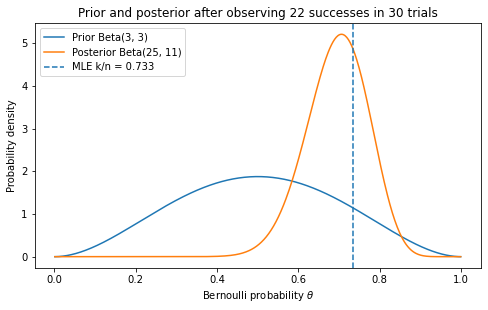

Prior mean: 0.5000
Observed frequency: 0.7333
Posterior mean: 0.6944
Posterior SD: 0.0757
95% equal-tailed credible interval: [0.537  0.8315]


In [2]:
n, k = 30, 22
alpha, beta_param = 3.0, 3.0
post_a, post_b = alpha + k, beta_param + n - k

theta_grid = np.linspace(0.001, 0.999, 500)
prior_density = stats.beta.pdf(theta_grid, alpha, beta_param)
posterior_density = stats.beta.pdf(theta_grid, post_a, post_b)

plt.figure(figsize=(8, 4.5))
plt.plot(theta_grid, prior_density, label=f"Prior Beta({alpha:g}, {beta_param:g})")
plt.plot(theta_grid, posterior_density, label=f"Posterior Beta({post_a:g}, {post_b:g})")
plt.axvline(k/n, linestyle='--', label=f"MLE k/n = {k/n:.3f}")
plt.xlabel(r"Bernoulli probability $\theta$")
plt.ylabel("Probability density")
plt.title("Prior and posterior after observing 22 successes in 30 trials")
plt.legend()
plt.show()

print(f"Prior mean: {alpha/(alpha+beta_param):.4f}")
print(f"Observed frequency: {k/n:.4f}")
print(f"Posterior mean: {post_a/(post_a+post_b):.4f}")
print(f"Posterior SD: {stats.beta.std(post_a,post_b):.4f}")
print(f"95% equal-tailed credible interval: {stats.beta.ppf([0.025,0.975],post_a,post_b)}")

**Observation.** The prior is symmetric around $0.5$. The posterior is shifted toward the observed frequency and is more concentrated. The MLE $k/n$ uses only the likelihood; the posterior mean also incorporates the prior's pseudo-counts. The credible interval describes posterior uncertainty about $\theta$, not variability in new Bernoulli outcomes.

## 2. A posterior probability that is easier to estimate than a posterior expectation
*Exercises 7.1.13–7.1.14; selected contrast.*

Under the location Normal model $X_i\sim N(\mu,\sigma_0^2)$ and Normal prior $\mu\sim N(\mu_0,\tau_0^2)$, the posterior is $N(\mu_n,\tau_n^2)$ with

$$
\tau_n^2=\left(\tau_0^{-2}+n\sigma_0^{-2}\right)^{-1}, \qquad
\mu_n=\tau_n^2\left(\mu_0\tau_0^{-2}+n\bar x\sigma_0^{-2}\right).
$$

The textbook asks about the coefficient of variation $\sigma_0/\mu$. For a **positive threshold** $c$ and $\sigma_0>0$,

$$
\Pr\!\left(\frac{\sigma_0}{\mu}>c\mid x\right)
=\Pr\!\left(0<\mu<\frac{\sigma_0}{c}\mid x\right).
$$

It is important to distinguish this probability from $E[\sigma_0/\mu\mid x]$. The latter **does not exist as an ordinary expectation** for a nondegenerate Normal posterior: the density is positive arbitrarily close to $\mu=0$, where $1/\mu$ is nonintegrable. A finite sample mean of $1/\mu$ cannot fix that mathematical problem.

In [3]:
mu0, tau0_sq, sigma0_sq = 2.0, 1.0, 1.0
n, xbar, c = 20, 8.2, 0.125
post_var = 1 / (1/tau0_sq + n/sigma0_sq)
post_mu = post_var * (mu0/tau0_sq + n*xbar/sigma0_sq)
post_sd = np.sqrt(post_var)
sigma0 = np.sqrt(sigma0_sq)

posterior_mu_draws = rng.normal(post_mu, post_sd, 10_000)
indicator = (posterior_mu_draws > 0) & (posterior_mu_draws < sigma0/c)
mc, mc_se = monte_carlo_summary(indicator)
exact = stats.norm.cdf((sigma0/c-post_mu)/post_sd) - stats.norm.cdf(-post_mu/post_sd)
show_mc_interval(mc, mc_se, "P(sigma0/mu > 0.125 | x)")
print(f"Exact Normal CDF benchmark: {exact:.6f}")
print("Do not interpret an average of sigma0/mu as an estimate of a finite posterior mean.")

P(sigma0/mu > 0.125 | x): 0.661900
MC standard error: 0.004731
Approximate ±3 SE range: [0.647707, 0.676093]
Exact Normal CDF benchmark: 0.668740
Do not interpret an average of sigma0/mu as an estimate of a finite posterior mean.


## 3. Posterior Monte Carlo and its numerical error
*Exercise 7.3.8.*

Suppose $n=100$ manufactured items are tested, with $k=5$ defective. The defect rate has prior $\theta\sim\operatorname{Beta}(0.5,10)$. The posterior is

$$
\theta\mid x\sim\operatorname{Beta}(5.5,105).
$$

We estimate $\Pr(\theta<0.1\mid x)$ from $N=1000$ independent posterior draws. For indicator values $I_i=\mathbf{1}_{\{\theta^{(i)}<0.1\}}$, the Monte Carlo estimator is $\hat p_N=N^{-1}\sum_i I_i$ and its estimated standard error is approximately

$$
\widehat{\mathrm{SE}}_{\rm MC}(\hat p_N)=\sqrt{\frac{\hat p_N(1-\hat p_N)}{N}}.
$$

Threshold 0.10: MC=0.9810, MC SE=0.0043, exact=0.9798
Threshold 0.05: MC=0.5700, MC SE=0.0157, exact=0.5568


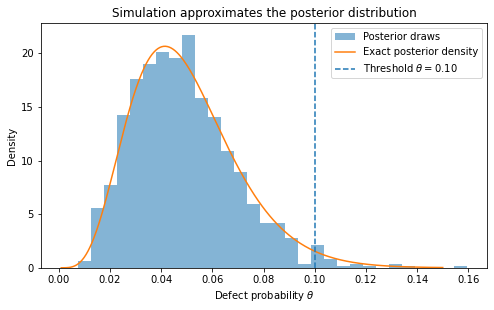

In [4]:
n, k, a0, b0 = 100, 5, 0.5, 10
post_a, post_b = a0 + k, b0 + n - k
thresholds = [0.10, 0.05]  # 0.10 is the original problem; 0.05 is an instructive extension.
N = 1000
posterior_samples = rng.beta(post_a, post_b, size=N)

for threshold in thresholds:
    flags = posterior_samples < threshold
    estimate, se = monte_carlo_summary(flags)
    exact = stats.beta.cdf(threshold, post_a, post_b)
    print(f"Threshold {threshold:.2f}: MC={estimate:.4f}, MC SE={se:.4f}, exact={exact:.4f}")

plt.figure(figsize=(8, 4.5))
plt.hist(posterior_samples, bins=30, density=True, alpha=0.55, label="Posterior draws")
xs = np.linspace(0.001, 0.15, 400)
plt.plot(xs, stats.beta.pdf(xs, post_a, post_b), label="Exact posterior density")
plt.axvline(0.10, linestyle="--", label=r"Threshold $\theta=0.10$")
plt.xlabel(r"Defect probability $\theta$")
plt.ylabel("Density")
plt.legend()
plt.title("Simulation approximates the posterior distribution")
plt.show()

**Observation.** Increasing $N$ reduces Monte Carlo error at the approximate rate $1/\sqrt N$, **without changing the posterior distribution**. The original threshold $0.10$ leads to a probability close to 1; comparing it with $0.05$ makes the role of event probability in Monte Carlo error more visible. Because the posterior is conjugate, we can compare our simulation with an exact Beta CDF.

## 4. Sampling a joint posterior to estimate a derived quantity
*Exercise 7.3.7, using Example 7.3.1.*

A location–scale Normal model has both $\mu$ and $\sigma^2$ unknown. With the conjugate Normal–Gamma construction in the textbook, we can first draw a **precision** and then a conditional Normal mean:

$$
\lambda=\frac1{\sigma^2}\mid x\sim\operatorname{Gamma}(\alpha_x,\beta_x),\qquad
\mu\mid\sigma^2,x\sim N\!\left(\mu_x,\frac{\sigma^2}{n+1/\tau_0^2}\right).
$$

Here Gamma uses **shape–rate** parameterization; NumPy's `gamma` uses shape–**scale**, so the scale must be $1/\beta_x$. We use the example's reported values $n=15$, $\mu_x=5.161$, $\alpha_x=9.5$, $\beta_x=77.578$, and $\tau_0^2=2$.

Our target is the *population first quartile*

$$\psi=\mu+\sigma z_{0.25}, \qquad z_{0.25}=\Phi^{-1}(0.25).$$

This derived parameter is more complicated than $\mu$ alone, but **each joint posterior draw directly yields a draw of $\psi$**.

Posterior first-quartile mean (N=5000): 3.155314
MC standard error: 0.012006
Approximate ±3 SE range: [3.119296, 3.191333]
Posterior first-quartile mean (N=10000): 3.155176
MC standard error: 0.008427
Approximate ±3 SE range: [3.129895, 3.180457]


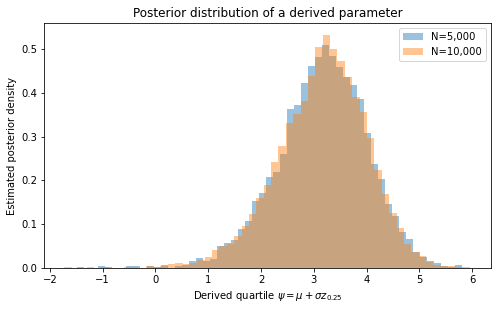

In [5]:
n = 15
mu_x, alpha_x, beta_x, tau0_sq = 5.161, 9.5, 77.578, 2.0
z25 = stats.norm.ppf(0.25)

def draw_first_quartile(N, rng):
    precision = rng.gamma(shape=alpha_x, scale=1/beta_x, size=N)
    sigma = np.sqrt(1/precision)
    mu = rng.normal(loc=mu_x, scale=sigma/np.sqrt(n + 1/tau0_sq))
    psi = mu + sigma*z25
    return psi

quartile_5k = draw_first_quartile(5_000, rng)
quartile_10k = draw_first_quartile(10_000, rng)
for vals in (quartile_5k, quartile_10k):
    est, se = monte_carlo_summary(vals)
    show_mc_interval(est, se, f"Posterior first-quartile mean (N={len(vals)})")

plt.figure(figsize=(8, 4.5))
plt.hist(quartile_5k, bins=55, density=True, alpha=.45, label="N=5,000")
plt.hist(quartile_10k, bins=55, density=True, alpha=.45, label="N=10,000")
plt.xlabel(r"Derived quartile $\psi=\mu+\sigma z_{0.25}$")
plt.ylabel("Estimated posterior density")
plt.title("Posterior distribution of a derived parameter")
plt.legend()
plt.show()

**Observation.** Sampling from the **joint** posterior preserves dependence between $\mu$ and $\sigma^2$. We should not sample the two quantities independently from their marginals when constructing this derived parameter. The posterior histogram and the Monte Carlo estimate answer different questions: the first describes the *distribution of $\psi$*, while the second approximates its *posterior mean*.

## 5. An empirical-Bayes illustration: choosing a prior parameter from data
*Adapted from Exercises 7.4.13–7.4.14 and Example 7.4.3.*

For a Bernoulli sample with $k$ successes out of $n$, suppose the prior family is $\theta\sim\operatorname{Beta}(\lambda,\lambda)$, $\lambda>0$. The **prior predictive probability of the count** $K=k$ is

$$
\Pr(K=k\mid\lambda)
={n\choose k}\frac{B(k+\lambda,n-k+\lambda)}{B(\lambda,\lambda)}.
$$

We maximize this quantity with respect to the *hyperparameter* $\lambda$ (rather than maximizing the Bernoulli likelihood over $\theta$). The combinatorial term is constant in $\lambda$.

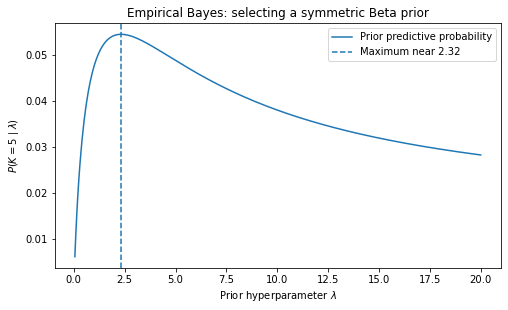

Empirical-Bayes lambda estimate: 2.322
Posterior given this choice: Beta(7.322, 17.322)


In [6]:
from scipy.special import gammaln

def beta_binomial_log_pmf(k, n, lam):
    return (gammaln(n+1)-gammaln(k+1)-gammaln(n-k+1)
            + betaln(k+lam, n-k+lam)-betaln(lam, lam))

n, k = 20, 5
lambdas = np.linspace(.05, 20, 400)
values = np.exp([beta_binomial_log_pmf(k, n, lam) for lam in lambdas])
opt = minimize_scalar(lambda lam: -beta_binomial_log_pmf(k, n, lam),
                      bounds=(0.05, 20), method="bounded")

plt.figure(figsize=(8, 4.5))
plt.plot(lambdas, values, label="Prior predictive probability")
plt.axvline(opt.x, linestyle="--", label=f"Maximum near {opt.x:.2f}")
plt.xlabel(r"Prior hyperparameter $\lambda$")
plt.ylabel(r"$P(K=5\mid\lambda)$")
plt.title("Empirical Bayes: selecting a symmetric Beta prior")
plt.legend()
plt.show()
print(f"Empirical-Bayes lambda estimate: {opt.x:.3f}")
print(f"Posterior given this choice: Beta({k+opt.x:.3f}, {n-k+opt.x:.3f})")

**Observation.** The optimum near $\lambda=2.3$ agrees with the textbook's illustrative result. This is a way to let data influence the prior's concentration, but it reuses the observed dataset in selecting the prior and performing inference. Therefore, the resulting posterior should not be interpreted as coming from a fully prespecified prior. A full hierarchical Bayesian approach would instead assign a probability distribution to $\lambda$.

# II. Optimal Inferences and Decision Theory
*Textbook: Chapter 8, especially §8.4 (Decision Theory).*

The central computational question is no longer only *"What estimate can I calculate?"* but *"Which decision is preferable under a specified cost of error?"* The **loss function** makes that cost explicit. The **risk function** summarizes average loss when observations vary across repeated samples.

These two illustrations complement the lecture's discussion of action spaces, posterior point estimation, and risk. The short optional power-function exercise at the end retains a classical statistical perspective.

## 6. One posterior, three different loss functions
*Supplementary illustration of §8.4; connects to posterior means and modes in §7.2.1.*

Assume a uniform prior for a Bernoulli success probability $\theta$, and observe one success in $n=5$ trials. Then

$$
\theta\mid s\sim\operatorname{Beta}(2,5).
$$

After observing data, an estimate $a\in[0,1]$ is an **action**. Instead of choosing $a$ by intuition, minimize the **posterior expected loss**

$$
\rho(a\mid s)=E[L(\theta,a)\mid s]
=\int_0^1 L(\theta,a)\,\pi(\theta\mid s)\,d\theta.
$$


Consider three possible ways to penalize estimation errors:

| Loss | Definition | Bayesian-optimal point estimate |
|:--|:--|:--|
| Squared-error | $$L_2(\theta,a)=(\theta-a)^2$$ | Posterior **mean** |
| Absolute-error | $$L_1(\theta,a)=\lvert\theta-a\rvert$$ | Posterior **median** |
| Outside a tolerance interval | $$L_\varepsilon(\theta,a)=\mathbf 1\{\lvert\theta-a\rvert>\varepsilon\}$$ | Center with the greatest posterior probability inside $$[a-\varepsilon,a+\varepsilon]$$ |


The third loss is a continuous-parameter, finite-tolerance counterpart to 0–1 loss. For a smooth posterior and sufficiently small $\varepsilon$, its best action approaches the **posterior mode (MAP)**. Exact pointwise 0–1 loss $\mathbf1\{\theta\ne a\}$ is **not informative for a continuous posterior**, because every individual point has posterior probability zero.

**Prediction:** The three optimal actions need not coincide for a skewed posterior. Use numerical integration to verify the relationship.

Squared-loss optimum = 0.2867; posterior mean = 0.2857
Absolute-loss optimum = 0.2633; posterior median = 0.2644
Tolerance-loss optimum = 0.1900; posterior mode = 0.2000


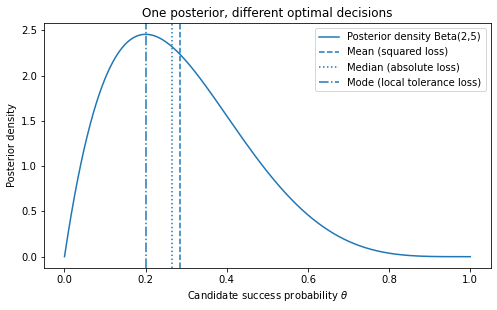

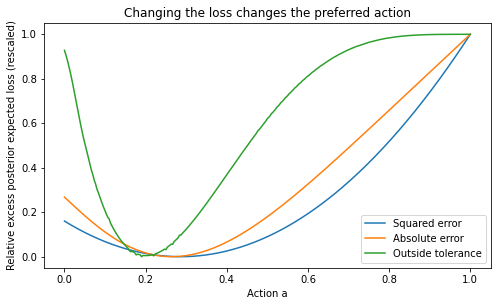

In [7]:
from scipy.integrate import trapezoid

# The posterior is Beta(2, 5): one success in five Bernoulli trials
shape_a, shape_b = 2.0, 5.0
theta = np.linspace(0.0, 1.0, 3001)
density = stats.beta.pdf(theta, shape_a, shape_b)
actions = np.linspace(0.0, 1.0, 301)
epsilon = 0.025

# A normalized quadrature approximates the posterior expected loss.
weights = density / trapezoid(density, theta)
errors = theta[None, :] - actions[:, None]

expected_squared = trapezoid(errors**2 * weights[None, :], theta, axis=1)
expected_absolute = trapezoid(np.abs(errors) * weights[None, :], theta, axis=1)
expected_tolerance = trapezoid((np.abs(errors) > epsilon) * weights[None, :], theta, axis=1)

optimal_sq = actions[np.argmin(expected_squared)]
optimal_abs = actions[np.argmin(expected_absolute)]
optimal_tol = actions[np.argmin(expected_tolerance)]

mean_exact = stats.beta.mean(shape_a, shape_b)
median_exact = stats.beta.median(shape_a, shape_b)
mode_exact = (shape_a - 1) / (shape_a + shape_b - 2)
print(f"Squared-loss optimum = {optimal_sq:.4f}; posterior mean = {mean_exact:.4f}")
print(f"Absolute-loss optimum = {optimal_abs:.4f}; posterior median = {median_exact:.4f}")
print(f"Tolerance-loss optimum = {optimal_tol:.4f}; posterior mode = {mode_exact:.4f}")

plt.figure(figsize=(8, 4.5))
plt.plot(theta, density, label="Posterior density Beta(2,5)")
plt.axvline(mean_exact, linestyle="--", label="Mean (squared loss)")
plt.axvline(median_exact, linestyle=":", label="Median (absolute loss)")
plt.axvline(mode_exact, linestyle="-.", label="Mode (local tolerance loss)")
plt.xlabel(r"Candidate success probability $\theta$")
plt.ylabel("Posterior density")
plt.title("One posterior, different optimal decisions")
plt.legend()
plt.show()

plt.figure(figsize=(8, 4.5))
for name, risks in [("Squared error", expected_squared),
                    ("Absolute error", expected_absolute),
                    ("Outside tolerance", expected_tolerance)]:
    # Scale each loss for comparison of minima, not comparison of loss units.
    scaled = (risks - risks.min()) / (risks.max() - risks.min())
    plt.plot(actions, scaled, label=name)
plt.xlabel("Action a")
plt.ylabel("Relative excess posterior expected loss (rescaled)")
plt.title("Changing the loss changes the preferred action")
plt.legend()
plt.show()

**Observation.** The data determine the posterior, but the **choice of loss determines the optimal summary of that posterior**. Thus, posterior mean, median, and mode are alternative decisions, not sequential steps in the same estimator. This is the reason Chapter 8's loss function clarifies choices introduced in Chapter 7. The finite grid/integration causes small numerical discrepancies from the exact mean, median, and mode.

## 7. Frequentist risk: comparing two estimators across true parameter values
*Supplementary illustration of §8.4 and the MSE criterion introduced in Chapter 8.*

Now consider repeated sampling, with a **fixed true** $\theta\in[0,1]$ and

$$K\sim\operatorname{Binomial}(n,\theta).$$

We compare the maximum likelihood estimator with the posterior mean under a uniform prior:

$$
\hat\theta_{\rm MLE}(K)=\frac K n,
\qquad
\hat\theta_{\rm Bayes}(K)=\frac{K+1}{n+2}.
$$

Under squared-error loss, the frequentist **risk** of a decision rule $d$ is

$$
R_d(\theta)=E_\theta[(d(K)-\theta)^2]
=\sum_{k=0}^{n}\Pr_\theta(K=k)\,(d(k)-\theta)^2.
$$

Compare the two curves for $n=8$. Importantly, this expectation is over **possible data samples given a fixed $\theta$**, whereas the preceding experiment's posterior expected loss was over **possible $\theta$ values given observed data**.

**Prediction:** Shrinkage toward $0.5$ may help for intermediate $\theta$, but it can introduce bias near the boundaries.

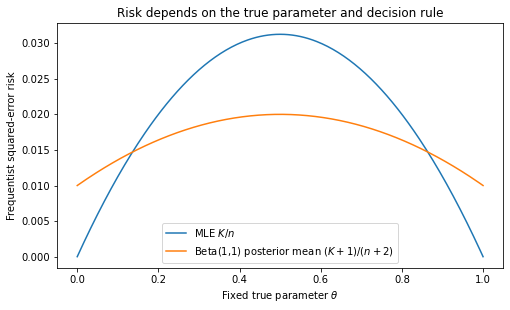

theta=0.00: MLE risk=0.00000; Bayes-rule risk=0.01000
theta=0.25: MLE risk=0.02344; Bayes-rule risk=0.01750
theta=0.50: MLE risk=0.03125; Bayes-rule risk=0.02000
theta=0.75: MLE risk=0.02344; Bayes-rule risk=0.01750
theta=1.00: MLE risk=0.00000; Bayes-rule risk=0.01000
Neither rule has a smaller squared-error risk for every theta.


In [8]:
n_risk = 8
possible_k = np.arange(n_risk + 1)
theta_values = np.linspace(0.0, 1.0, 301)
ml_actions = possible_k / n_risk
bayes_actions = (possible_k + 1) / (n_risk + 2)

pmf = stats.binom.pmf(possible_k[None, :], n_risk, theta_values[:, None])
risk_ml = np.sum(pmf * (ml_actions[None, :] - theta_values[:, None])**2, axis=1)
risk_bayes = np.sum(pmf * (bayes_actions[None, :] - theta_values[:, None])**2, axis=1)

plt.figure(figsize=(8, 4.5))
plt.plot(theta_values, risk_ml, label=r"MLE $K/n$")
plt.plot(theta_values, risk_bayes, label=r"Beta(1,1) posterior mean $(K+1)/(n+2)$")
plt.xlabel(r"Fixed true parameter $\theta$")
plt.ylabel("Frequentist squared-error risk")
plt.title("Risk depends on the true parameter and decision rule")
plt.legend()
plt.show()

for t in [0.0, 0.25, 0.5, 0.75, 1.0]:
    j = np.argmin(np.abs(theta_values - t))
    print(f"theta={theta_values[j]:.2f}: MLE risk={risk_ml[j]:.5f}; "
          f"Bayes-rule risk={risk_bayes[j]:.5f}")
print("Neither rule has a smaller squared-error risk for every theta.")

**Observation.** The MLE has low risk at the boundary values $\theta=0$ and $\theta=1$, whereas the posterior-mean estimator trades a little boundary bias for lower risk around many interior values. Neither has uniformly lower frequentist risk for every true parameter. A decision rule cannot be called *optimal* without specifying the loss and the criterion for comparing risks.

**Connection to the lecture:** Minimizing average squared error is an important special case of risk minimization. In later machine learning, losses are also evaluated on observed datasets; the additional notion of *empirical risk* belongs to that subsequent development rather than the Chapter 8 derivation.

### Optional link to textbook Exercise 8.4.7: a test's power is also a decision-rule property

For a test of $H_0:\mu=0$ versus $H_a:\mu\ne0$, the action is to reject or not reject the null. Under **0–1 loss**, the risk at $\mu=0$ equals the type-I-error probability; for $\mu\ne0$, the risk is the type-II-error probability $1-\operatorname{power}(\mu)$. Thus a power curve is another way to evaluate a decision rule, though it is not this notebook's main Chapter 8 focus.

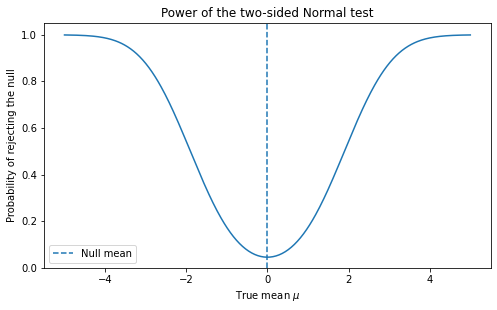

Type I error rate at mu=0: 0.0455
Power when mu=2: 0.5431


In [9]:
mu0, sigma0, n = 0.0, 3.0, 10
sd_xbar = sigma0 / np.sqrt(n)
L, U = mu0-2*sd_xbar, mu0+2*sd_xbar
mu_grid = np.linspace(-5, 5, 400)
power = stats.norm.cdf((L-mu_grid)/sd_xbar) + stats.norm.sf((U-mu_grid)/sd_xbar)

plt.figure(figsize=(8, 4.5))
plt.plot(mu_grid, power)
plt.axvline(mu0, linestyle="--", label="Null mean")
plt.xlabel(r"True mean $\mu$")
plt.ylabel("Probability of rejecting the null")
plt.title("Power of the two-sided Normal test")
plt.ylim(0, 1.05)
plt.legend()
plt.show()
print(f"Type I error rate at mu=0: {2*stats.norm.sf(2):.4f}")
print(f"Power when mu=2: {stats.norm.cdf((L-2)/sd_xbar)+stats.norm.sf((U-2)/sd_xbar):.4f}")

# III. Model Checking
*Textbook: Chapter 9.*

Inferences are conditional on assumptions. This chapter separates three questions: **(1)** Do the observed data plausibly match the sampling assumptions? **(2)** Does the model predict observations it was not fitted on? **(3)** For Bayesian inference, does the chosen prior conflict with the observations? The first and third are directly exercised in the textbook; the cross-validation experiment below is a clearly marked computational illustration of §9.1.3.

## 8. How much can a Normal probability plot vary at small sample size?
*Exercise 9.1.13, with an extension from Exercises 9.1.15–9.1.17.*

A Normal quantile–quantile (Q–Q) plot compares ordered observed values $x_{(i)}$ with theoretical Normal quantiles $z_i=\Phi^{-1}((i-0.5)/n)$. **Approximate linearity** supports compatibility with the Normal model; it does not prove normality.

Generate 25 separate samples of size $n=10$ from $N(0,1)$ and overlay their Q–Q traces. Because $n$ is small, visible deviations from a reference straight line can occur even under the correct model.

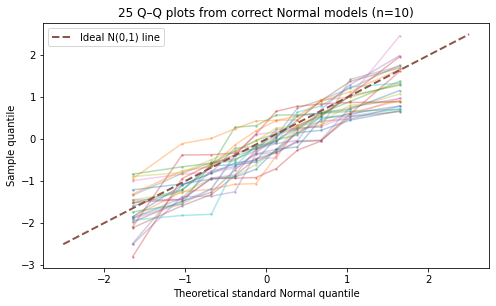

In [10]:
num_datasets, n = 25, 10
theoretical = stats.norm.ppf((np.arange(1, n+1)-0.5)/n)

plt.figure(figsize=(8, 4.5))
for _ in range(num_datasets):
    observed = np.sort(rng.normal(size=n))
    plt.plot(theoretical, observed, marker=".", markersize=3, alpha=0.35)
plt.plot([-2.5,2.5],[-2.5,2.5], linestyle="--", linewidth=2, label="Ideal N(0,1) line")
plt.xlabel("Theoretical standard Normal quantile")
plt.ylabel("Sample quantile")
plt.title("25 Q–Q plots from correct Normal models (n=10)")
plt.legend()
plt.show()

### A complementary formal check: chi-squared goodness-of-fit
*Streamlined version of Exercise 9.1.17.*

For a fixed $N(0,1)$ null model, generate $1000$ observations and sort them into five bins with equal theoretical probabilities $p_j=0.2$. The Pearson statistic is

$$
D=\sum_{j=1}^{5}\frac{(O_j-E_j)^2}{E_j}, \qquad E_j=1000(0.2)=200.
$$

Since these Normal parameters are specified rather than fitted from this dataset, the reference distribution is approximately $\chi^2(4)$. If the parameters were estimated from the same observations, the reference degrees of freedom would generally need adjustment.

In [11]:
N = 1000
simulated = rng.normal(size=N)
edges = np.concatenate(([-np.inf], stats.norm.ppf([0.2,0.4,0.6,0.8]), [np.inf]))
observed, _ = np.histogram(simulated, bins=edges)
expected = np.full(5, N/5)
pearson = np.sum((observed-expected)**2/expected)
p_value = stats.chi2.sf(pearson, df=4)
print("Observed cell counts:", observed)
print("Expected cell counts:", expected.astype(int))
print(f"Pearson statistic = {pearson:.3f}; reference df = 4; P-value = {p_value:.4f}")

Observed cell counts: [187 187 224 192 210]
Expected cell counts: [200 200 200 200 200]
Pearson statistic = 5.390; reference df = 4; P-value = 0.2496


**Observation.** A sample truly generated from the null distribution can produce a small P-value by chance; a large P-value is not proof of correctness. Likewise, with a large enough sample, a model can be rejected for deviations too small to affect its practical predictive usefulness. Graphical and numerical checks are complementary.

## 9. From residual checking to cross-validation
*Supplementary computational illustration of textbook §9.1.3 (Prediction and Cross-Validation), with residual checking from §9.1.1.*

Fitting a model and checking it answer different questions. A residual plot asks whether there is **structure left unexplained by the fitted model**. Cross-validation asks whether a model's performance on training observations extends to **held-out observations**.

Construct data from a noisy quadratic relationship (a simulated example, **not** a textbook dataset):

$$
Y=1+0.3X-1.7X^2+\varepsilon, \qquad \varepsilon\sim N(0,0.25^2).
$$

Fit polynomials of degree $1$, $2$, $8$, and $12$. Degree 1 cannot represent the curvature. The very high-degree models have many coefficients relative to the dataset size and may follow noise rather than the underlying relationship.

For each candidate model we calculate

$$
\mathrm{MSE}_{\rm train}=\frac1n\sum_{i=1}^n (y_i-\hat y_i)^2,
\qquad
\mathrm{MSE}_{\rm CV}=\frac1n\sum_{i=1}^n (y_i-\hat y_i^{(-f(i))})^2,
$$

where $\hat y_i^{(-f(i))}$ is predicted by a fit that **excludes the fold containing observation $i$**. This is five-fold cross-validation: each observation is predicted once when it is held out. The textbook introduces the train/validation-split principle; five-fold repetition is a small supplementary extension.

**Prediction:** A more flexible model can always improve or match its *training* error, but its *held-out* error need not improve.

Degree  1: training MSE=1.3725; five-fold CV MSE=1.4925
Degree  2: training MSE=0.0352; five-fold CV MSE=0.0392
Degree  8: training MSE=0.0329; five-fold CV MSE=0.0610
Degree 12: training MSE=0.0276; five-fold CV MSE=0.5524


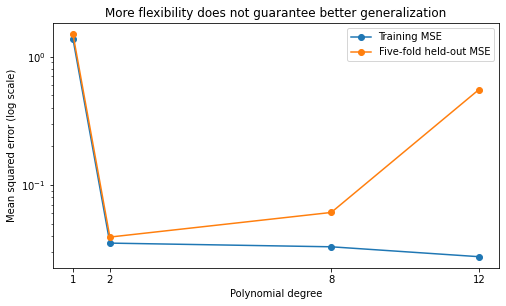

In [12]:
# Generate the same synthetic dataset for every candidate model.
cv_rng = np.random.default_rng(21)
n_cv = 45
x_cv = cv_rng.uniform(-1.5, 1.5, size=n_cv)
y_cv = 1.0 + 0.3*x_cv - 1.7*x_cv**2 + cv_rng.normal(0.0, 0.25, size=n_cv)

# Chebyshev polynomial features provide a numerically stable basis on [-1, 1].
# This changes the basis, not the set of degree-d polynomial predictions.
x_scaled = x_cv / 1.5
folds = np.array_split(cv_rng.permutation(n_cv), 5)
degrees = [1, 2, 8, 12]
training_mse, heldout_mse = [], []
full_predictions = {}

for degree in degrees:
    design = np.polynomial.chebyshev.chebvander(x_scaled, degree)
    full_coef = np.linalg.lstsq(design, y_cv, rcond=None)[0]
    in_sample = design @ full_coef
    full_predictions[degree] = in_sample
    training_mse.append(np.mean((y_cv - in_sample)**2))

    out_of_fold = np.empty(n_cv)
    for valid_idx in folds:
        train_idx = np.setdiff1d(np.arange(n_cv), valid_idx)
        fold_coef = np.linalg.lstsq(design[train_idx], y_cv[train_idx], rcond=None)[0]
        out_of_fold[valid_idx] = design[valid_idx] @ fold_coef
    heldout_mse.append(np.mean((y_cv - out_of_fold)**2))

for degree, train_err, cv_err in zip(degrees, training_mse, heldout_mse):
    print(f"Degree {degree:2d}: training MSE={train_err:.4f}; five-fold CV MSE={cv_err:.4f}")

plt.figure(figsize=(8, 4.5))
plt.plot(degrees, training_mse, marker="o", label="Training MSE")
plt.plot(degrees, heldout_mse, marker="o", label="Five-fold held-out MSE")
plt.yscale("log")
plt.xticks(degrees)
plt.xlabel("Polynomial degree")
plt.ylabel("Mean squared error (log scale)")
plt.title("More flexibility does not guarantee better generalization")
plt.legend()
plt.show()

### Residual diagnostic: why is the linear model inadequate?

Plot residuals against $x$ for the degree-1 and degree-2 fits. For a correctly specified conditional-mean model, there should not be systematic curvature remaining in the residuals. This diagnostic is complementary to cross-validation: one examines **patterns of mismatch**, the other evaluates **held-out predictive error**.

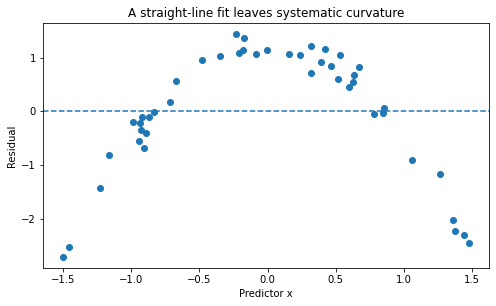

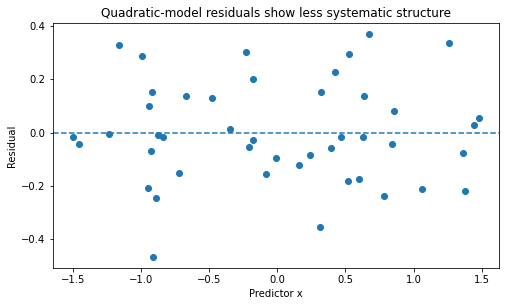

Best degree by this particular five-fold CV: 2


In [13]:
order = np.argsort(x_cv)
plt.figure(figsize=(8, 4.5))
plt.scatter(x_cv, y_cv - full_predictions[1], label="Linear-model residuals")
plt.axhline(0, linestyle="--")
plt.xlabel("Predictor x")
plt.ylabel("Residual")
plt.title("A straight-line fit leaves systematic curvature")
plt.show()

plt.figure(figsize=(8, 4.5))
plt.scatter(x_cv, y_cv - full_predictions[2], label="Quadratic-model residuals")
plt.axhline(0, linestyle="--")
plt.xlabel("Predictor x")
plt.ylabel("Residual")
plt.title("Quadratic-model residuals show less systematic structure")
plt.show()

print("Best degree by this particular five-fold CV:", degrees[int(np.argmin(heldout_mse))])

**Observation.** The linear fit leaves a curved residual pattern and has relatively large held-out error: evidence of **underfitting**. The degree-12 model has the smallest training error but noticeably worse held-out error than the quadratic fit: evidence of **overfitting** in this dataset. In another finite sample, cross-validation rankings can vary, so no single split or set of folds provides a guarantee.

**Scope note.** This synthetic example illustrates the textbook's prediction/cross-validation principle. Selecting hyperparameters, separating validation from a final test set, and designing full ML pipelines belong to the subsequent machine-learning material.

## 10. Prior–data conflict using the prior predictive distribution
*Exercise 9.2.6.*

A Bernoulli sample has $n=20$ trials and $k=6$ successes, with prior $\theta\sim\operatorname{Beta}(3,3)$. The **sampling family** of Bernoulli distributions allows $k=6$. The separate question is whether this observation is surprising *under the chosen prior*.

Integrating over $\theta$ yields the Beta–Binomial distribution of the sufficient statistic $K$:

$$
\Pr(K=k)=\binom nk\frac{B(k+\alpha,n-k+\beta)}{B(\alpha,\beta)}.
$$

A possible discrete prior-predictive conflict check sums the probabilities of all $k'$ whose predictive probability is at most as large as that of the observation:

$$
p_{\rm conflict}=\sum_{k':\, m(k')\leq m(k_{\rm obs})}m(k').
$$

This is a **prior-predictive tail check**, not the posterior probability that the prior is correct.

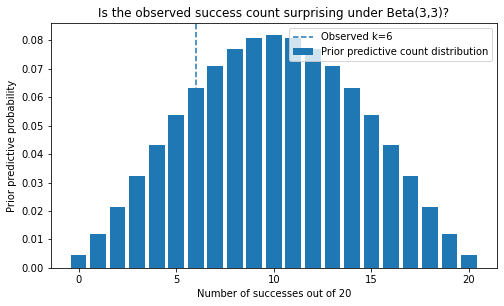

P(K=6) = 0.06324
Probability-ordering conflict check = 0.4601


In [14]:
n, k_obs, a0, b0 = 20, 6, 3, 3
counts = np.arange(n+1)
prior_predictive = stats.betabinom.pmf(counts, n, a0, b0)
observed_mass = prior_predictive[k_obs]
conflict_p = prior_predictive[prior_predictive <= observed_mass + 1e-12].sum()

plt.figure(figsize=(8, 4.5))
plt.bar(counts, prior_predictive, label="Prior predictive count distribution")
plt.axvline(k_obs, linestyle="--", label=f"Observed k={k_obs}")
plt.xlabel("Number of successes out of 20")
plt.ylabel("Prior predictive probability")
plt.title("Is the observed success count surprising under Beta(3,3)?")
plt.legend()
plt.show()
print(f"P(K=6) = {observed_mass:.5f}")
print(f"Probability-ordering conflict check = {conflict_p:.4f}")

**Observation.** The result is not a strong signal of prior–data conflict under this particular check. This says nothing conclusive about whether the Bernoulli sampling assumptions (such as independence and identical success probability) are correct; those should be evaluated separately. The distinction mirrors the textbook's sequence: check the sampling model, then consider prior–data compatibility.

### Chapter 9 synthesis

The Q–Q and discrepancy-statistic exercises concern **plausibility of a sampling model**. Cross-validation concerns **predictive behavior beyond fitted data**. The Beta–Binomial calculation checks whether the **prior and observed sufficient statistic are compatible** under the chosen Bayesian model. None replaces the others; together they explain why fitting a model is not the last step of statistical analysis.

# IV. Relationships Among Variables
*Textbook: Chapter 10.*

Regression provides the most substantial practical bridge in this notebook. Each fitted model will be accompanied by inference or diagnostics, rather than treating a numerical coefficient estimate as the end of the analysis. The residual diagnostics in this chapter apply the model-checking ideas of Chapter 9 to the textbook's observed datasets; cross-validation remains a separate check of predictive performance.

## 11. Simple linear regression from raw measurements
*Exercise 10.3.15: aluminum tensile strength and hardness.*

We observe $n=20$ measurements. The predictor $x$ is Rockwell E hardness and the response $y$ is tensile strength in units of $100\,\mathrm{lb}/\mathrm{in}^2$.

Assume a linear conditional mean:

$$
E(Y\mid X=x)=\beta_0+\beta_1 x.
$$

For $X\in\mathbb R^{20\times 2}$ (an intercept column and a hardness column), least squares minimizes

$$
\|y-X\beta\|_2^2,
\qquad \hat\beta=(X^TX)^{-1}X^Ty
$$

when $X$ has full column rank. In code, prefer `np.linalg.lstsq` over explicitly computing a matrix inverse.

Design matrix shape: (20, 2) rank: 2
Fitted line: Strength = 168.854 + 2.144 * Hardness
Residual sum of squares = 12246.44; R^2 = 0.5858


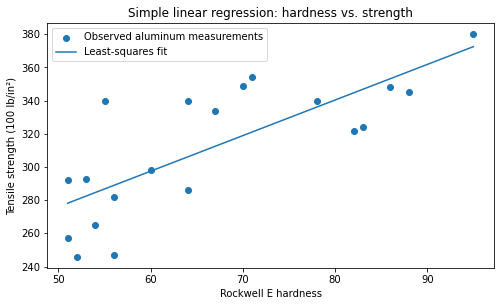

In [15]:
hardness = np.array([53,70,78,55,64,71,82,67,56,86,60,51,95,88,51,54,52,64,83,56], dtype=float)
strength = np.array([293,349,340,340,340,354,322,334,247,348,298,292,380,345,257,265,246,286,324,282], dtype=float)

n = hardness.size
X_simple = np.column_stack((np.ones(n), hardness))
b_simple, _, rank, _ = np.linalg.lstsq(X_simple, strength, rcond=None)
yhat = X_simple @ b_simple
residuals = strength - yhat
SSE = residuals @ residuals
SST = ((strength-strength.mean())**2).sum()
R2_simple = 1-SSE/SST

print("Design matrix shape:", X_simple.shape, "rank:", rank)
print(f"Fitted line: Strength = {b_simple[0]:.3f} + {b_simple[1]:.3f} * Hardness")
print(f"Residual sum of squares = {SSE:.2f}; R^2 = {R2_simple:.4f}")

plt.figure(figsize=(8, 4.5))
plt.scatter(hardness, strength, label="Observed aluminum measurements")
xx = np.linspace(hardness.min(), hardness.max(), 200)
plt.plot(xx, b_simple[0]+b_simple[1]*xx, label="Least-squares fit")
plt.xlabel("Rockwell E hardness")
plt.ylabel("Tensile strength (100 lb/in²)")
plt.title("Simple linear regression: hardness vs. strength")
plt.legend()
plt.show()

### Inference and uncertainty

Under independent errors with $E(\epsilon_i\mid X)=0$ and common conditional variance $\sigma^2$, the covariance matrix of the estimated coefficients, conditional on the design, is

$$
\operatorname{Cov}(\hat\beta\mid X)=\sigma^2(X^TX)^{-1}.
$$

Estimate $\sigma^2$ by $s^2=\mathrm{SSE}/(n-2)$. Normal errors additionally justify exact $t$-based confidence intervals and tests. The confidence interval for the conditional **mean** at $x_*$ is narrower than a prediction interval for a **new observation** at $x_*$ because the latter includes irreducible observation noise.

In [16]:
p = X_simple.shape[1]
resid_df = n-p
s2_simple = SSE / resid_df
cov_simple = s2_simple * np.linalg.inv(X_simple.T @ X_simple)
se_coef = np.sqrt(np.diag(cov_simple))
tcrit = stats.t.ppf(.975, resid_df)
ci_simple = np.column_stack((b_simple - tcrit*se_coef, b_simple + tcrit*se_coef))
t_slope = b_simple[1]/se_coef[1]
p_slope = 2*stats.t.sf(abs(t_slope), resid_df)
print("Coefficient estimates:", b_simple)
print("Coefficient standard errors:", se_coef)
print("95% coefficient CIs (intercept, slope):\n", ci_simple)
print(f"Slope two-sided t-test P-value: {p_slope:.6f}")
print(f"R²: {R2_simple:.4f}; sample-correlation squared: {np.corrcoef(hardness,strength)[0,1]**2:.4f}")

x_star = 70.0
v_star = np.array([1, x_star])
mean_est = v_star @ b_simple
se_mean = np.sqrt(v_star @ cov_simple @ v_star)
se_future = np.sqrt(se_mean**2 + s2_simple)
print(f"At hardness={x_star:g}, estimated mean strength={mean_est:.2f}")
print("95% CI for conditional mean:", mean_est + np.array([-1,1])*tcrit*se_mean)
print("95% prediction interval for a new response:", mean_est + np.array([-1,1])*tcrit*se_future)

Coefficient estimates: [168.8538   2.1444]
Coefficient standard errors: [28.981  0.425]
95% coefficient CIs (intercept, slope):
 [[107.9669 229.7407]
 [  1.2516   3.0372]]
Slope two-sided t-test P-value: 0.000084
R²: 0.5858; sample-correlation squared: 0.5858
At hardness=70, estimated mean strength=318.96
95% CI for conditional mean: [306.3798 331.5444]
95% prediction interval for a new response: [262.7364 375.1878]


### Check the fitted assumptions

Residuals $e_i=y_i-\hat y_i$ should not show systematic curvature or a strong change in spread across predictor values. A Normal probability plot provides another check when Normal errors are used to justify exact $t$ and $F$ inference.

The **internally standardized residuals** divide each residual by $s\sqrt{1-h_{ii}}$, where the leverage $h_{ii}$ is the $i$th diagonal element of the hat matrix $H=X(X^TX)^{-1}X^T$. This accounts for the fact that fitted residuals can have different variances even under homoscedastic observation errors.

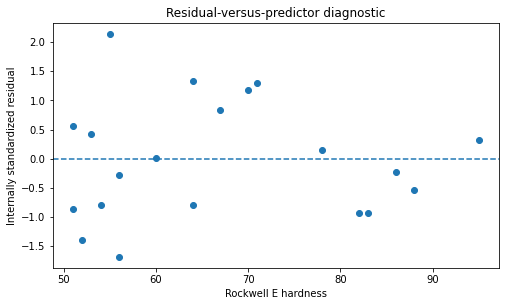

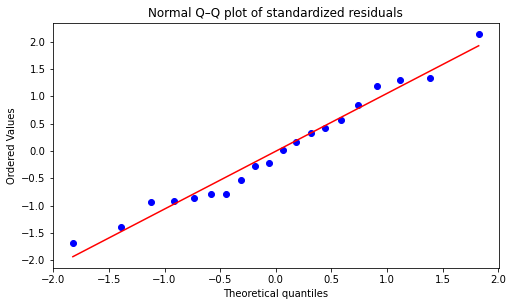

In [17]:
leverage_simple = np.sum((X_simple @ np.linalg.inv(X_simple.T@X_simple))*X_simple, axis=1)
r_standardized = residuals / (np.sqrt(s2_simple)*np.sqrt(1-leverage_simple))

plt.figure(figsize=(8, 4.5))
plt.scatter(hardness, r_standardized)
plt.axhline(0, linestyle="--")
plt.xlabel("Rockwell E hardness")
plt.ylabel("Internally standardized residual")
plt.title("Residual-versus-predictor diagnostic")
plt.show()

plt.figure(figsize=(8, 4.5))
stats.probplot(r_standardized, dist="norm", plot=plt)
plt.title("Normal Q–Q plot of standardized residuals")
plt.show()

**Observation.** The fitted slope is positive, but the points have noticeable scatter and the fit is far from perfect. Use the residual and Q–Q plots to assess whether the Normal straight-line model is plausible before leaning on its exact inferential formulas. A positive slope is **association**, not automatically a causal effect of hardness on strength. $R^2$ summarizes the variation represented in this dataset; it does not certify out-of-sample accuracy.

## 12. Multiple linear regression and testing a predictor conditionally
*Exercise 10.3.16: gas-stream tar content, rotor speed, and temperature.*

The observed response is tar content; predictors are rotor speed and gas inlet temperature. Use the Normal linear model

$$
Y_i=\beta_0+\beta_1\,\mathrm{Speed}_i+\beta_2\,\mathrm{Temperature}_i+\epsilon_i,
\qquad \epsilon_i\sim N(0,\sigma^2).
$$

The full design matrix has dimensions $X\in\mathbb R^{10\times 3}$. We estimate the coefficients by least squares and compare the full model with a **reduced model omitting speed but retaining temperature**. This tests the contribution of speed *given that temperature is already in the model*.

In [18]:
tar = np.array([60,65,63.5,44,54.5,26,54,53.5,33.5,44],dtype=float)
speed = np.array([2400,2450,2500,2700,2700,2775,2800,2900,3075,3150],dtype=float)
temperature = np.array([54.5,58.5,58,62.5,68,45.5,63,64.5,57,64],dtype=float)
n = len(tar)
X_multi = np.column_stack([np.ones(n), speed, temperature])
coef_multi, _, rank_multi, _ = np.linalg.lstsq(X_multi, tar, rcond=None)
fit_multi = X_multi @ coef_multi
resid_multi = tar-fit_multi
SSE_full = resid_multi@resid_multi
p_full = X_multi.shape[1]
s2_multi = SSE_full/(n-p_full)
cov_multi = s2_multi * np.linalg.inv(X_multi.T@X_multi)
se_multi = np.sqrt(np.diag(cov_multi))
tcrit_multi = stats.t.ppf(.975, n-p_full)
ci_multi = np.column_stack([coef_multi-tcrit_multi*se_multi, coef_multi+tcrit_multi*se_multi])

print("Full design shape:", X_multi.shape, "rank:", rank_multi)
print("Coefficients [intercept, speed, temperature]:", coef_multi)
print("Standard errors:", se_multi)
print("95% CIs:\n", ci_multi)
print("R²:", 1-SSE_full/((tar-tar.mean())**2).sum())

Full design shape: (10, 3) rank: 3
Coefficients [intercept, speed, temperature]: [87.6923 -0.0406  1.2333]
Standard errors: [29.016   0.0092  0.3599]
95% CIs:
 [[ 19.0804 156.3042]
 [ -0.0622  -0.0189]
 [  0.3821   2.0844]]
R²: 0.7856169279923112


### Global and partial $F$ tests

For the full model with $p=3$ parameters (including intercept), the global null $H_0:\beta_1=\beta_2=0$ is tested by

$$
F_{\rm global} = \frac{(\mathrm{SST}-\mathrm{SSE}_{\rm full})/(p-1)}{\mathrm{SSE}_{\rm full}/(n-p)}.
$$

To test speed after accounting for temperature, define $\mathrm{SSE}_{\rm reduced}$ from the intercept+temperature model. The partial statistic is

$$
F_{\rm partial}=\frac{(\mathrm{SSE}_{\rm reduced}-\mathrm{SSE}_{\rm full})/(p_{\rm full}-p_{\rm reduced})}{\mathrm{SSE}_{\rm full}/(n-p_{\rm full})}.
$$

This is a useful way to ask whether adding a predictor contributes information not already represented by other predictors.

In [19]:
SST_multi = ((tar-tar.mean())**2).sum()
F_global = ((SST_multi-SSE_full)/(p_full-1)) / s2_multi
p_global = stats.f.sf(F_global, p_full-1, n-p_full)

X_reduced = X_multi[:,[0,2]] # no speed, but keep intercept and temperature
b_reduced = np.linalg.lstsq(X_reduced, tar, rcond=None)[0]
resid_reduced = tar-X_reduced@b_reduced
SSE_reduced = resid_reduced@resid_reduced
F_partial = ((SSE_reduced-SSE_full)/1) / s2_multi
p_partial = stats.f.sf(F_partial,1,n-p_full)

print(f"SSE (full) = {SSE_full:.3f}")
print(f"SSE (reduced) = {SSE_reduced:.3f}")
print(f"Global F({p_full-1},{n-p_full}) = {F_global:.3f}; P={p_global:.5f}")
print(f"Partial F(1,{n-p_full}) for speed | temperature = {F_partial:.3f}; P={p_partial:.5f}")
assert SSE_full <= SSE_reduced + 1e-8

SSE (full) = 316.344
SSE (reduced) = 1203.696
Global F(2,7) = 12.826; P=0.00456
Partial F(1,7) for speed | temperature = 19.635; P=0.00304


### Residual diagnostics and a new fitted mean

We check residuals against *both* predictors. For $v_*=(1,\mathrm{speed}_*,\mathrm{temperature}_*)$, the fitted conditional mean is $\hat y_*=v_*^T\hat\beta$ and its standard error is $s\sqrt{v_*^T(X^TX)^{-1}v_*}$. Predicting a **new response** would additionally include the observation noise $s^2$.

A new predictor combination may be individually within observed ranges but still be unusual relative to the observed **joint** predictor configurations. Thus, “inside each marginal range” is not always enough to label a multivariate prediction reliably as interpolation.

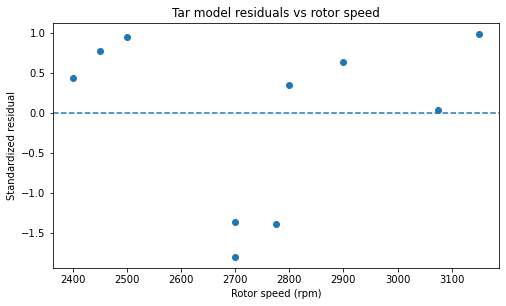

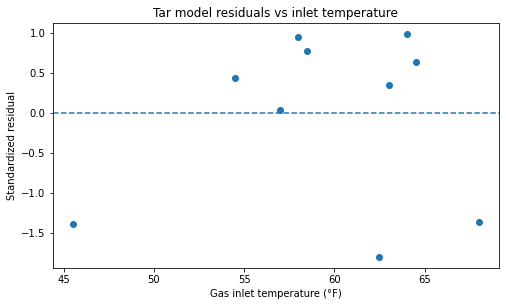

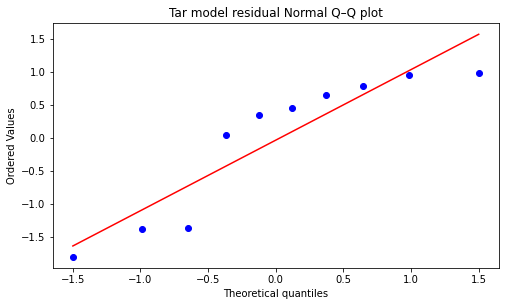

Fitted conditional mean at speed=2750 and temperature=50: 37.819
95% CI for fitted conditional mean: [28.2399 47.3988]
Speed and temperature both lie in observed marginal ranges: True True


In [20]:
leverage_multi = np.sum((X_multi @ np.linalg.inv(X_multi.T@X_multi))*X_multi,axis=1)
std_multi = resid_multi/(np.sqrt(s2_multi)*np.sqrt(1-leverage_multi))

plt.figure(figsize=(8,4.5))
plt.scatter(speed, std_multi)
plt.axhline(0, linestyle="--")
plt.xlabel("Rotor speed (rpm)")
plt.ylabel("Standardized residual")
plt.title("Tar model residuals vs rotor speed")
plt.show()

plt.figure(figsize=(8,4.5))
plt.scatter(temperature, std_multi)
plt.axhline(0, linestyle="--")
plt.xlabel("Gas inlet temperature (°F)")
plt.ylabel("Standardized residual")
plt.title("Tar model residuals vs inlet temperature")
plt.show()

plt.figure(figsize=(8,4.5))
stats.probplot(std_multi,dist="norm",plot=plt)
plt.title("Tar model residual Normal Q–Q plot")
plt.show()

new_case = np.array([1,2750,50.0])
y_est = new_case @ coef_multi
se_est = np.sqrt(new_case @ cov_multi @ new_case)
print(f"Fitted conditional mean at speed=2750 and temperature=50: {y_est:.3f}")
print("95% CI for fitted conditional mean:", y_est+np.array([-1,1])*tcrit_multi*se_est)
print("Speed and temperature both lie in observed marginal ranges:",
      speed.min()<=2750<=speed.max(), temperature.min()<=50<=temperature.max())

**Observation.** Multiple regression measures the contribution of predictors **conditional on each other**. The partial $F$ test is not interchangeable with a marginal correlation test. With only 10 observations, confidence intervals and Q–Q plots should be interpreted cautiously, and the model's reliability depends on its error and functional-form assumptions.

## 13. Logistic regression: modeling a binary response by maximum likelihood
*Exercise 10.5.7.*

The observed $Y\in\{0,1\}$ values are two independent outcomes at each $x\in\{-5,-4,\ldots,5\}$. A linear probability model is not ideal because it need not stay in $[0,1]$. Instead define

$$
p(x)=\Pr(Y=1\mid x)=\frac{1}{1+e^{-\eta(x)}}, \qquad
\eta(x)=\beta_0+\beta_1 x+\beta_2 x^2.
$$

This is logistic regression with a quadratic feature. **The regression is linear in the coefficients**, even though its log-odds are quadratic in $x$. For independent observations, the negative log-likelihood is

$$
-\ell(\beta)=\sum_i\left[\log\!\left(1+e^{\eta_i}\right)-y_i\eta_i\right].
$$

`np.logaddexp(0, eta)` implements $\log(1+e^\eta)$ stably, avoiding overflow for large $\eta$.

In [21]:
x_logit = np.repeat(np.arange(-5,6, dtype=float),2)
y_logit = np.array([0,0, 0,0, 0,0, 0,0, 1,0, 0,0,
                    1,0, 0,1, 1,1, 1,1, 1,1],dtype=float)
assert len(x_logit)==len(y_logit)==22

def fit_logistic(x, y, degree):
    design = np.column_stack([x**j for j in range(degree+1)])
    def nll(beta):
        eta = design@beta
        return np.logaddexp(0,eta).sum()-y@eta
    def gradient(beta):
        return design.T@(expit(design@beta)-y)
    result = minimize(nll, np.zeros(degree+1), jac=gradient, method="BFGS",
                      options={"gtol":1e-8, "maxiter":1000})
    if not np.isfinite(result.fun) or np.max(np.abs(gradient(result.x)))>1e-5:
        raise RuntimeError("Logistic fit failed to converge sufficiently")
    return result

linear_logit = fit_logistic(x_logit,y_logit,1)
quadratic_logit = fit_logistic(x_logit,y_logit,2)
print("Linear logit beta:", linear_logit.x, "NLL:", linear_logit.fun)
print("Quadratic logit beta:", quadratic_logit.x, "NLL:", quadratic_logit.fun)

Linear logit beta: [-1.0063  0.9969] NLL: 6.432271302790319
Quadratic logit beta: [-1.185   0.9436  0.0597] NLL: 6.35382579640612


### Compare linear and quadratic log-odds

The models are nested: the simpler model assumes $\beta_2=0$. An approximate likelihood-ratio test uses

$$
G^2=2\left[\ell(\hat\beta_{\rm quadratic})-\ell(\hat\beta_{\rm linear})\right]
=2\left[\mathrm{NLL}_{\rm linear}-\mathrm{NLL}_{\rm quadratic}\right],
$$

with approximate $\chi^2(1)$ reference distribution under standard large-sample regularity conditions. Given the small dataset, the asymptotic $P$-value should be treated as indicative rather than exact.

Likelihood-ratio statistic: 0.1569; approximate P-value: 0.6920


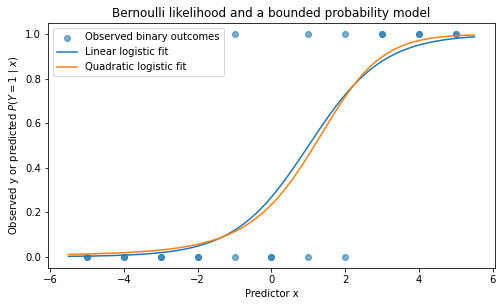

x=-4 -> estimated P(Y=1|x)=0.0067 (linear logit)
x=+0 -> estimated P(Y=1|x)=0.2677 (linear logit)
x=+4 -> estimated P(Y=1|x)=0.9517 (linear logit)


In [22]:
LR = 2*(linear_logit.fun-quadratic_logit.fun)
p_LR = stats.chi2.sf(LR,df=1)
print(f"Likelihood-ratio statistic: {LR:.4f}; approximate P-value: {p_LR:.4f}")

x_grid = np.linspace(-5.5,5.5,450)
plt.figure(figsize=(8,4.5))
plt.scatter(x_logit,y_logit,alpha=.6,label="Observed binary outcomes")
plt.plot(x_grid,expit(linear_logit.x[0]+linear_logit.x[1]*x_grid),
         label="Linear logistic fit")
plt.plot(x_grid,expit(quadratic_logit.x[0]+quadratic_logit.x[1]*x_grid+
                      quadratic_logit.x[2]*x_grid**2),label="Quadratic logistic fit")
plt.xlabel("Predictor x")
plt.ylabel(r"Observed y or predicted $P(Y=1\mid x)$")
plt.ylim(-.05,1.05)
plt.legend()
plt.title("Bernoulli likelihood and a bounded probability model")
plt.show()

for x0 in (-4,0,4):
    p_linear = expit(linear_logit.x[0]+linear_logit.x[1]*x0)
    print(f"x={x0:+d} -> estimated P(Y=1|x)={p_linear:.4f} (linear logit)")

**Observation.** Both logistic curves map real-valued linear predictors to valid probabilities. The quadratic model achieves at least as high a training likelihood, because it has an extra coefficient; that alone is not evidence it is necessary. The likelihood-ratio statistic evaluates whether the additional flexibility is supported by the observed sample, subject to the approximation. The exercise connects Bernoulli likelihoods, numerical optimization, and interpretable probability predictions.

# V. Summary

## 14. Consolidating the computational workflow

These experiments make the statistical workflow concrete:

| Stage | Computation in this notebook | What it answers |
|:--|:--|:--|
| Bayesian updating | Beta and Normal posteriors | How does information about an unknown parameter change? |
| Posterior simulation | Monte Carlo draws, indicators, derived quartiles | How can we approximate posterior quantities and report numerical error? |
| Prior choice | Prior predictive optimization | What happens if a prior hyperparameter is chosen from observations? |
| Decisions and loss | Posterior expected squared/absolute/tolerance losses | Why do different estimators minimize different costs? |
| Frequentist risk | Exact repeated-sampling squared-error curves and optional power | How does decision quality change across true parameter values? |
| Sampling-model checking | Q–Q plots, chi-squared statistics, residuals | Are observed patterns compatible with sampling assumptions? |
| Cross-validation | Five-fold held-out prediction errors | Does a more flexible model actually predict unseen observations better? |
| Prior–data compatibility | Beta–Binomial prior predictive check | Does the prior assign plausible probability to the observed data? |
| Linear regression | Least squares, CIs, residuals, $R^2$, partial $F$ | How does a quantitative response depend on predictors? |
| Logistic regression | Stable Bernoulli likelihood optimization, nested comparison | How do we fit a binary outcome model with valid probabilities? |

### Important distinctions worth retaining

1. **Posterior uncertainty is not Monte Carlo error:** increasing posterior draws improves numerical precision, not the statistical information in the dataset.
2. **A finite simulated average does not establish the existence of an expectation:** the reciprocal-Normal caution in Section 2 is an example.
3. **Loss is not risk:** loss evaluates a particular error; frequentist risk averages that loss over possible datasets at a fixed parameter. Posterior expected loss averages over the posterior after data are observed.
4. **Fitting is not checking or validation:** residuals and goodness-of-fit diagnostics inspect assumptions; cross-validation evaluates predictive behavior on held-out data.
5. **Better training fit is not automatically better generalization:** compare the purpose and complexity of the models, not only their fitted likelihood or $R^2$.

### Implementation notes

**Dependencies:** `numpy`, `scipy`, `matplotlib`. The code requires no `statsmodels` or `scikit-learn`, so its linear algebra and likelihood computations are visible.

**Companion:** `probability_foundations_part5_main_notes_v5.ipynb` develops the associated concepts and mathematics. The two notebooks intentionally use the same Chapter 7–10 progression; this exercise file focuses on computations rather than reproducing all derivations. A concise README can later orient GitHub visitors to both files.